<a href="https://colab.research.google.com/github/Moulyabuilds/blood-group-fingerprint/blob/main/notebooks/blood_group_training.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
from google.colab import drive
drive.mount('/content/drive')
!unzip -q /content/drive/MyDrive/dataset.zip -d /content
!ls /content/dataset

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
dataset_blood_group


Classes: ['A+', 'A-', 'AB+', 'AB-', 'B+', 'B-', 'O+', 'O-'] | total images: 6000
train per class: [396 706 496 533 456 519 596 498]
val   per class: [ 84 152 106 114  98 111 128 107]
test  per class: [ 85 151 106 114  98 111 128 107]
Epoch 1/30
132/132 ━━━━━━━━━━━━━━━━━━━━ 15s 48ms/step - accuracy: 0.4019 - loss: 1.5364 - val_accuracy: 0.1178 - val_loss: 2.3124 - learning_rate: 0.0010
Epoch 2/30
132/132 ━━━━━━━━━━━━━━━━━━━━ 5s 40ms/step - accuracy: 0.5457 - loss: 1.1808 - val_accuracy: 0.1178 - val_loss: 4.1707 - learning_rate: 0.0010
Epoch 3/30
132/132 ━━━━━━━━━━━━━━━━━━━━ 6s 42ms/step - accuracy: 0.6229 - loss: 1.0048 - val_accuracy: 0.2933 - val_loss: 3.7024 - learning_rate: 0.0010
Epoch 4/30
132/132 ━━━━━━━━━━━━━━━━━━━━ 5s 40ms/step - accuracy: 0.6638 - loss: 0.8965 - val_accuracy: 0.3700 - val_loss: 2.3353 - learning_rate: 0.0010
Epoch 5/30
132/132 ━━━━━━━━━━━━━━━━━━━━ 5s 41ms/step - accuracy: 0.7067 - loss: 0.7829 - val_accuracy: 0.5411 - val_loss: 1.3501 - learning_rate: 5.0000e

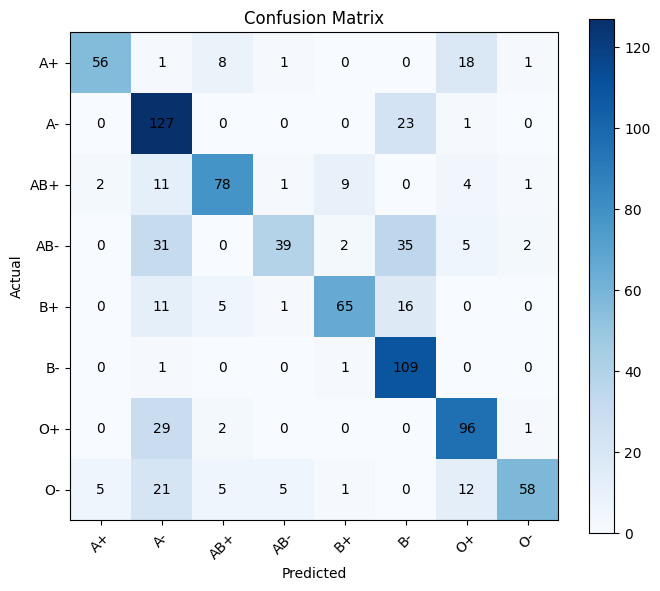

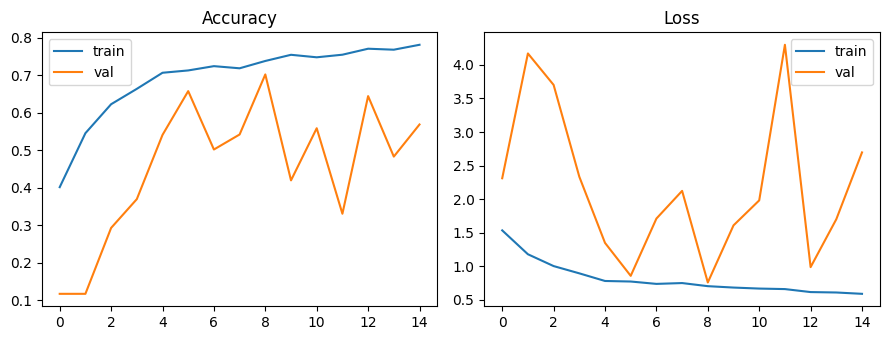

Saved model


In [8]:
import os, json
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix

DATA_DIR = "/content/dataset/dataset_blood_group"
IMG_SIZE = (128, 128)
BATCH = 32
EPOCHS = 30
SEED = 42
AUTOTUNE = tf.data.AUTOTUNE

# ---- 1. List all files and labels ----
class_names = sorted(d for d in os.listdir(DATA_DIR)
                     if os.path.isdir(os.path.join(DATA_DIR, d)))
num_classes = len(class_names)
paths, labels = [], []
for i, c in enumerate(class_names):
    for f in os.listdir(os.path.join(DATA_DIR, c)):
        paths.append(os.path.join(DATA_DIR, c, f))
        labels.append(i)
paths, labels = np.array(paths), np.array(labels)
print("Classes:", class_names, "| total images:", len(paths))

# ---- 2. Stratified split: 70% train, 15% val, 15% test ----
tr_p, tmp_p, tr_y, tmp_y = train_test_split(
    paths, labels, test_size=0.30, stratify=labels, random_state=SEED)
va_p, te_p, va_y, te_y = train_test_split(
    tmp_p, tmp_y, test_size=0.50, stratify=tmp_y, random_state=SEED)

print("train per class:", np.bincount(tr_y))
print("val   per class:", np.bincount(va_y))
print("test  per class:", np.bincount(te_y))

# ---- 3. Data pipeline (BMP -> RGB -> resize -> grayscale) ----
def load(path, label):
    img = tf.io.read_file(path)
    img = tf.io.decode_image(img, channels=3, expand_animations=False)
    img = tf.image.resize(img, IMG_SIZE)
    img = tf.image.rgb_to_grayscale(img)
    img.set_shape(IMG_SIZE + (1,))
    return img, label

def make_ds(p, y, training):
    ds = tf.data.Dataset.from_tensor_slices((p, y))
    ds = ds.map(load, num_parallel_calls=AUTOTUNE).cache()
    if training:
        ds = ds.shuffle(len(p), seed=SEED)
    return ds.batch(BATCH).prefetch(AUTOTUNE)

train_ds = make_ds(tr_p, tr_y, True)
val_ds = make_ds(va_p, va_y, False)
test_ds = make_ds(te_p, te_y, False)

# ---- 4. Model ----
model = models.Sequential([
    layers.Input(shape=IMG_SIZE + (1,)),
    layers.Rescaling(1.0 / 255),
    layers.RandomRotation(0.05),
    layers.RandomZoom(0.1),
    layers.Conv2D(32, 3, activation="relu", padding="same"),
    layers.BatchNormalization(),
    layers.MaxPooling2D(),
    layers.Conv2D(64, 3, activation="relu", padding="same"),
    layers.BatchNormalization(),
    layers.MaxPooling2D(),
    layers.Conv2D(128, 3, activation="relu", padding="same"),
    layers.BatchNormalization(),
    layers.MaxPooling2D(),
    layers.GlobalAveragePooling2D(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.5),
    layers.Dense(num_classes, activation="softmax"),
])
model.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
              loss="sparse_categorical_crossentropy",
              metrics=["accuracy"])

callbacks = [
    tf.keras.callbacks.EarlyStopping(patience=6, restore_best_weights=True),
    tf.keras.callbacks.ReduceLROnPlateau(patience=3, factor=0.5),
]
history = model.fit(train_ds, validation_data=val_ds,
                    epochs=EPOCHS, callbacks=callbacks)

# ---- 5. Evaluate on the test set ----
y_true, y_pred = [], []
for x, y in test_ds:
    probs = model.predict(x, verbose=0)
    y_pred.extend(np.argmax(probs, axis=1))
    y_true.extend(y.numpy())

print("\nTest accuracy:", np.mean(np.array(y_true) == np.array(y_pred)))
print(classification_report(y_true, y_pred, labels=list(range(num_classes)),
                            target_names=class_names, zero_division=0))

cm = confusion_matrix(y_true, y_pred, labels=list(range(num_classes)))
plt.figure(figsize=(7, 6))
plt.imshow(cm, cmap="Blues")
plt.title("Confusion Matrix")
plt.xticks(range(num_classes), class_names, rotation=45)
plt.yticks(range(num_classes), class_names)
for i in range(num_classes):
    for j in range(num_classes):
        plt.text(j, i, cm[i, j], ha="center", va="center")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.colorbar()
plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=150)
plt.show()

plt.figure(figsize=(9, 3.5))
plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="train")
plt.plot(history.history["val_accuracy"], label="val")
plt.title("Accuracy"); plt.legend()
plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="train")
plt.plot(history.history["val_loss"], label="val")
plt.title("Loss"); plt.legend()
plt.tight_layout()
plt.savefig("training_curves.png", dpi=150)
plt.show()

model.save("blood_cnn.keras")
with open("class_names.json", "w") as f:
    json.dump(class_names, f)
print("Saved model")

In [5]:
import os
for root, dirs, files in os.walk("/content/dataset"):
    depth = root.count(os.sep) - 2
    if depth <= 2:
        print("  " * depth + os.path.basename(root) + "/", "-", len(files), "files")


dataset/ - 0 files
  dataset_blood_group/ - 0 files
    O-/ - 712 files
    AB-/ - 761 files
    A+/ - 565 files
    B+/ - 652 files
    AB+/ - 708 files
    B-/ - 741 files
    O+/ - 852 files
    A-/ - 1009 files
